In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('Resume.csv')

In [18]:
!pip install nltk

## 1. Cleaning the CSV

In [19]:
df = df.drop('Resume_html', axis=1, errors='ignore')

# cleans the text by removing special characters, numbers, and extra spaces, and converting to lowercase
def clean_text(text):
    text = str(text).lower() 
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip() 
    return text

df['Clean_Resume'] = df['Resume_str'].apply(clean_text)

df.head()

,ID,Resume_str,Category,Clean_Resume
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR,hr administratormarketing associate hr adminis...
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...",HR,hr specialist us hr operations summary versati...
2,33176873,HR DIRECTOR Summary Over 2...,HR,hr director summary over years experience in r...
3,27018550,HR SPECIALIST Summary Dedica...,HR,hr specialist summary dedicated driven and dyn...
4,17812897,HR MANAGER Skill Highlights ...,HR,hr manager skill highlights hr skills hr depar...


## 2. CV Word count

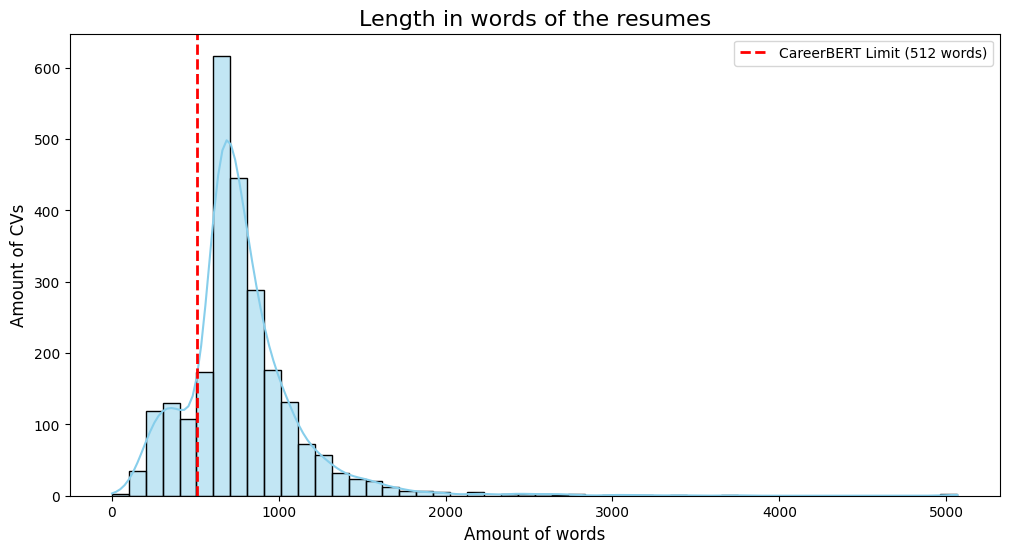

In [27]:
# counts and adds a new column for the number of words in each cleaned resume
df['Word_Count'] = df['Clean_Resume'].apply(lambda x: len(x.split()))

# histogram
plt.figure(figsize=(12,6))
sns.histplot(df['Word_Count'], bins=50, color='skyblue', kde=True)
plt.axvline(x=512, color='red', linestyle='--', linewidth=2, label='CareerBERT Limit (512 words)')

plt.title('Length in words of the resumes', fontsize=16)
plt.xlabel('Amount of words', fontsize=12)
plt.ylabel('Amount of CVs', fontsize=12)
plt.legend()
plt.show()


Many CVs contain more words than CareerBERT would process (above 512), meaning the rest would be cut off. This proves we need the Truncation Classifier described the paper, an algorithm that shortens the words.

## 3. Amount of CVs per industry group 

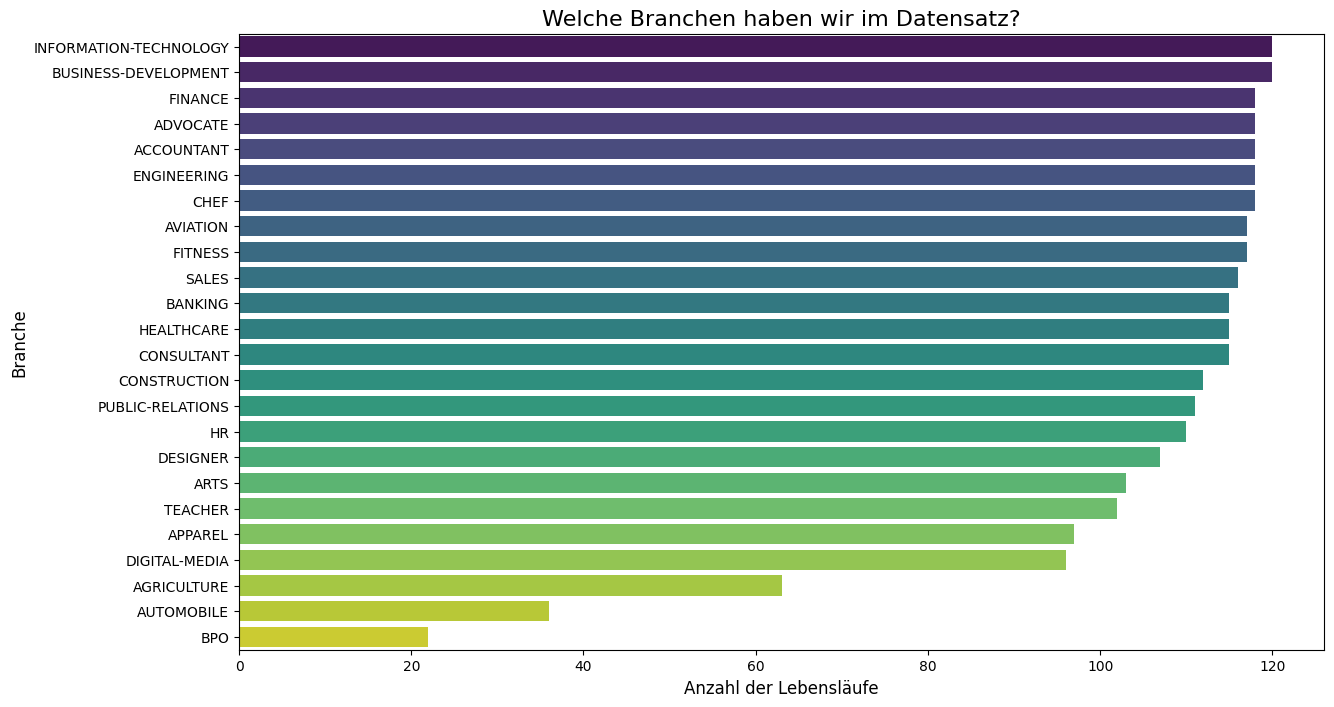

In [8]:
plt.figure(figsize=(14,8))
sns.countplot(data=df, y='Category', order=df['Category'].value_counts().index, palette='viridis')
plt.title('Welche Branchen haben wir im Datensatz?', fontsize=16)
plt.xlabel('Anzahl der Lebensläufe', fontsize=12)
plt.ylabel('Branche', fontsize=12)
plt.show()

## 4. CHECK: does dataset contain proxies/biased wording

In [21]:
from collections import Counter

# example: we analyze the most common words in HR resumes
hr_text = " ".join(df[df['Category'] == 'HR']['Clean_Resume'])
hr_words = hr_text.split()

word_counts = Counter(hr_words)

#  remove stop words and very short words < 3 characters
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

filtered_words = {word: count for word, count in word_counts.items() if word not in stop_words and len(word) > 2}

top_20 = Counter(filtered_words).most_common(20)
print("Die 20 häufigsten Wörter in HR-Lebensläufen:")
for word, count in top_20:
    print(f"{word}: {count}")

Die 20 häufigsten Wörter in HR-Lebensläufen:
management: 935
employee: 797
company: 703
state: 655
human: 592
city: 565
employees: 502
training: 494
name: 455
new: 434
resources: 413
benefits: 376
business: 376
skills: 373
development: 339
performance: 314
process: 310
policies: 304
payroll: 298
recruitment: 288


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/nadialitzenburger/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


The most common words in the HR industry group for example don't show clear biases -> we must use a different approach

### 4a). Option to find proxies: create a list of typical stereotyped keywords and check for those

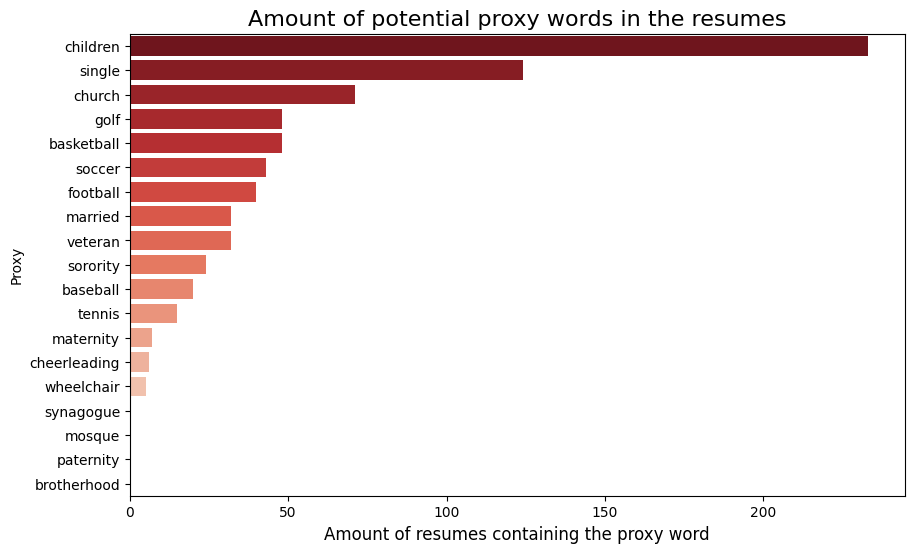

In [26]:
# define keywords that could indicate potential bias in the resumes
bias_keywords = [
    'brotherhood', 'sorority', 'maternity', 'paternity', 'church', 
    'mosque', 'synagogue', 'football', 'cheerleading', 'veteran', 
    'wheelchair', 'married', 'single', 'children', 'football', 'basketball', 'baseball', 'soccer', 'tennis', 'golf'
]

# check in cleaned csv
bias_counts = {}
for word in bias_keywords:
    count = df['Clean_Resume'].str.contains(f"\\b{word}\\b").sum()
    bias_counts[word] = count

bias_df = pd.DataFrame(list(bias_counts.items()), columns=['Proxy', 'Anzahl'])
bias_df = bias_df.sort_values(by='Anzahl', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=bias_df, x='Anzahl', y='Proxy', palette='Reds_r')
plt.title('Amount of potential proxy words in the resumes', fontsize=16)
plt.xlabel('Amount of resumes containing the proxy word', fontsize=12)
plt.show()

This shows that many of the datasets cvs contain biased wording/PROXIES, just using example keywords